<a href="https://colab.research.google.com/github/datadigger01/Datahandling/blob/main/Code_example/week10_outlier_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv('/content/drive/MyDrive/데이터처리실무/Data/Kor_Ramen_Export_by_Year.csv',encoding="utf-8-sig")
print(df.info())
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 813 entries, 0 to 812
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Year                813 non-null    int64  
 1   ISO2C               813 non-null    object 
 2   balPayments         813 non-null    int64  
 3   expDlr              813 non-null    int64  
 4   expWgt              813 non-null    int64  
 5   impWgt              813 non-null    int64  
 6   impDlr              813 non-null    int64  
 7   Import_Country      813 non-null    object 
 8   Exp_Item            813 non-null    object 
 9   expWgt_2020b        813 non-null    int64  
 10  ratio_expWgt_2020b  813 non-null    float64
 11  iso3c               813 non-null    object 
 12  name                813 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 82.7+ KB
None


,Year,ISO2C,balPayments,expDlr,expWgt,impWgt,impDlr,Import_Country,Exp_Item,expWgt_2020b,ratio_expWgt_2020b,iso3c,name
0,2015,AE,1470020,1470020,275212,0,0,아랍에미리트 연합,라면,1196973,0.229923,ARE,United Arab Emirates
1,2015,AR,513384,513384,128065,0,0,아르헨티나,라면,70291,1.821926,ARG,Argentina
2,2015,AS,1111541,1111541,196202,0,0,아메리칸 사모아,라면,225128,0.871513,ASM,American Samoa
3,2015,AT,3863,3863,992,0,0,오스트리아,라면,82973,0.011956,AUT,Austria
4,2015,AU,11773727,11774071,3066170,34,344,호주,라면,6861871,0.446842,AUS,Australia
...,...,...,...,...,...,...,...,...,...,...,...,...,...
808,2025,US,254707684,254744425,51342782,1895,36741,미국,라면,21824859,2.352491,USA,United States of America
809,2025,UZ,6448632,6475032,1569579,14165,26400,우즈베키스탄,라면,152862,10.267948,UZB,Uzbekistan
810,2025,VN,23313522,26192394,6873710,590449,2878872,베트남,라면,5252100,1.308755,VNM,Viet Nam
811,2025,WS,2234923,2234923,447186,0,0,사모아,라면,258229,1.731742,WSM,Samoa


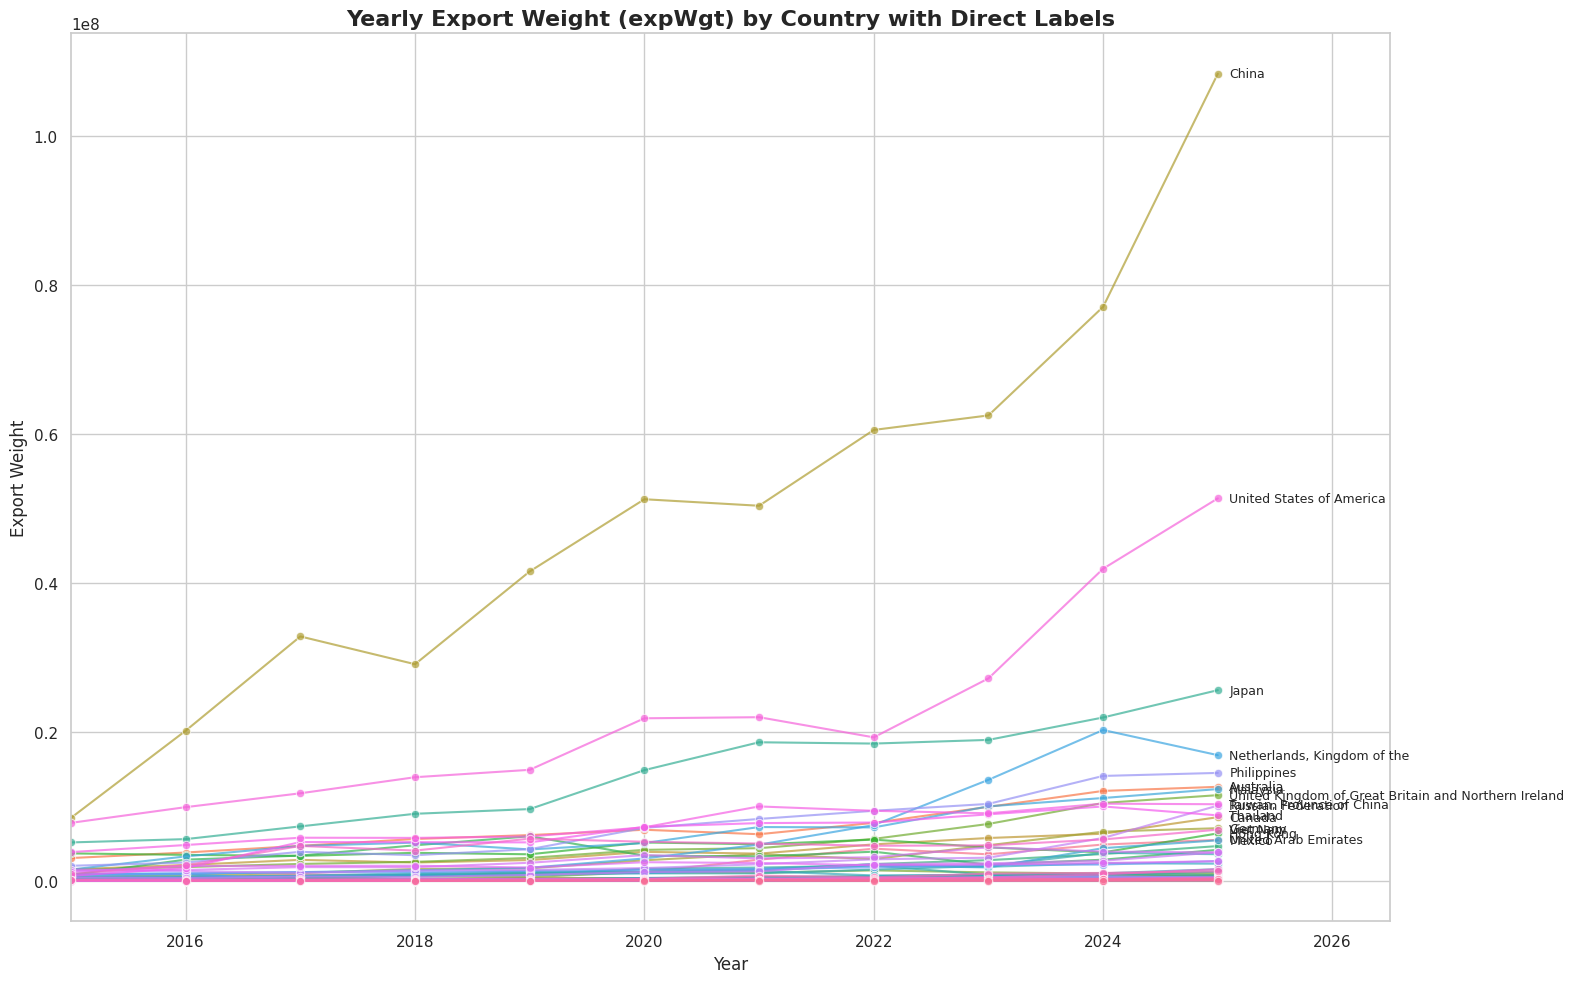

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 10))

# 선그래프 그리기 (범례는 우선 생성하지 않음: legend=False)
ax = sns.lineplot(
    data=df,
    x='Year',
    y='expWgt',
    hue='name',
    marker='o',
    alpha=0.7,
    legend=False
)

# 각 선의 끝(마지막 연도 데이터 위치)에 직접 국가 이름 표기하기
# 데이터의 가장 최근 연도인 2025년 기준 데이터를 가져옵니다.
last_year_data = df[df['Year'] == df['Year'].max()]

for _, row in last_year_data.iterrows():
    # 텍스트가 겹치는 것을 방지하기 위해 일정 수출물량 이상인 국가만 이름을 직접 표시하거나,
    # 모든 선 끝에 이름을 표시하도록 설정합니다.
    if row['expWgt'] > 5000000: # 보기 편하도록 일정 수출량 이상인 국가명만 직접 노출
        plt.text(
            x=row['Year'] + 0.1,
            y=row['expWgt'],
            s=row['name'],
            fontsize=9,
            va='center'
        )

plt.title('Yearly Export Weight (expWgt) by Country with Direct Labels', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Export Weight', fontsize=12)
plt.xlim(df['Year'].min(), df['Year'].max() + 1.5) # 텍스트가 들어갈 우측 여백 확보
plt.tight_layout()
plt.show()

In [10]:
# iso3c, name을 인덱스로 하고, Year를 컬럼으로 하여 ratio_expWgt_2020b 값을 피벗(전치)
pivoted_df = df.pivot_table(
    index=['iso3c', 'name'],
    columns='Year',
    values='ratio_expWgt_2020b',
    aggfunc='first'  # 연도별 국가 데이터가 유일하므로 'first' 사용
).reset_index()

# 결과 확인
pivoted_df.info()
display(pivoted_df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   iso3c   75 non-null     object 
 1   name    75 non-null     object 
 2   2015    71 non-null     float64
 3   2016    72 non-null     float64
 4   2017    72 non-null     float64
 5   2018    74 non-null     float64
 6   2019    74 non-null     float64
 7   2020    75 non-null     float64
 8   2021    75 non-null     float64
 9   2022    75 non-null     float64
 10  2023    75 non-null     float64
 11  2024    75 non-null     float64
 12  2025    75 non-null     float64
dtypes: float64(11), object(2)
memory usage: 7.7+ KB


Year,iso3c,name,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,ARE,United Arab Emirates,0.229923,0.398532,0.685157,0.652206,0.773987,1.0,2.376688,3.614071,2.979043,4.074435,4.600922
1,ARG,Argentina,1.821926,1.948571,2.570486,1.621033,2.267886,1.0,2.217738,2.904739,2.982103,3.708981,5.119389
2,ASM,American Samoa,0.871513,0.850991,0.688813,0.891502,0.952001,1.0,1.026345,1.267817,1.285629,1.333481,1.184024
3,AUS,Australia,0.446842,0.554995,0.685955,0.819636,0.895937,1.0,0.913011,1.135056,1.448530,1.759982,1.839792
4,AUT,Austria,0.011956,0.252697,0.276909,0.324117,0.506394,1.0,1.132212,1.446205,1.806624,1.443614,1.917479


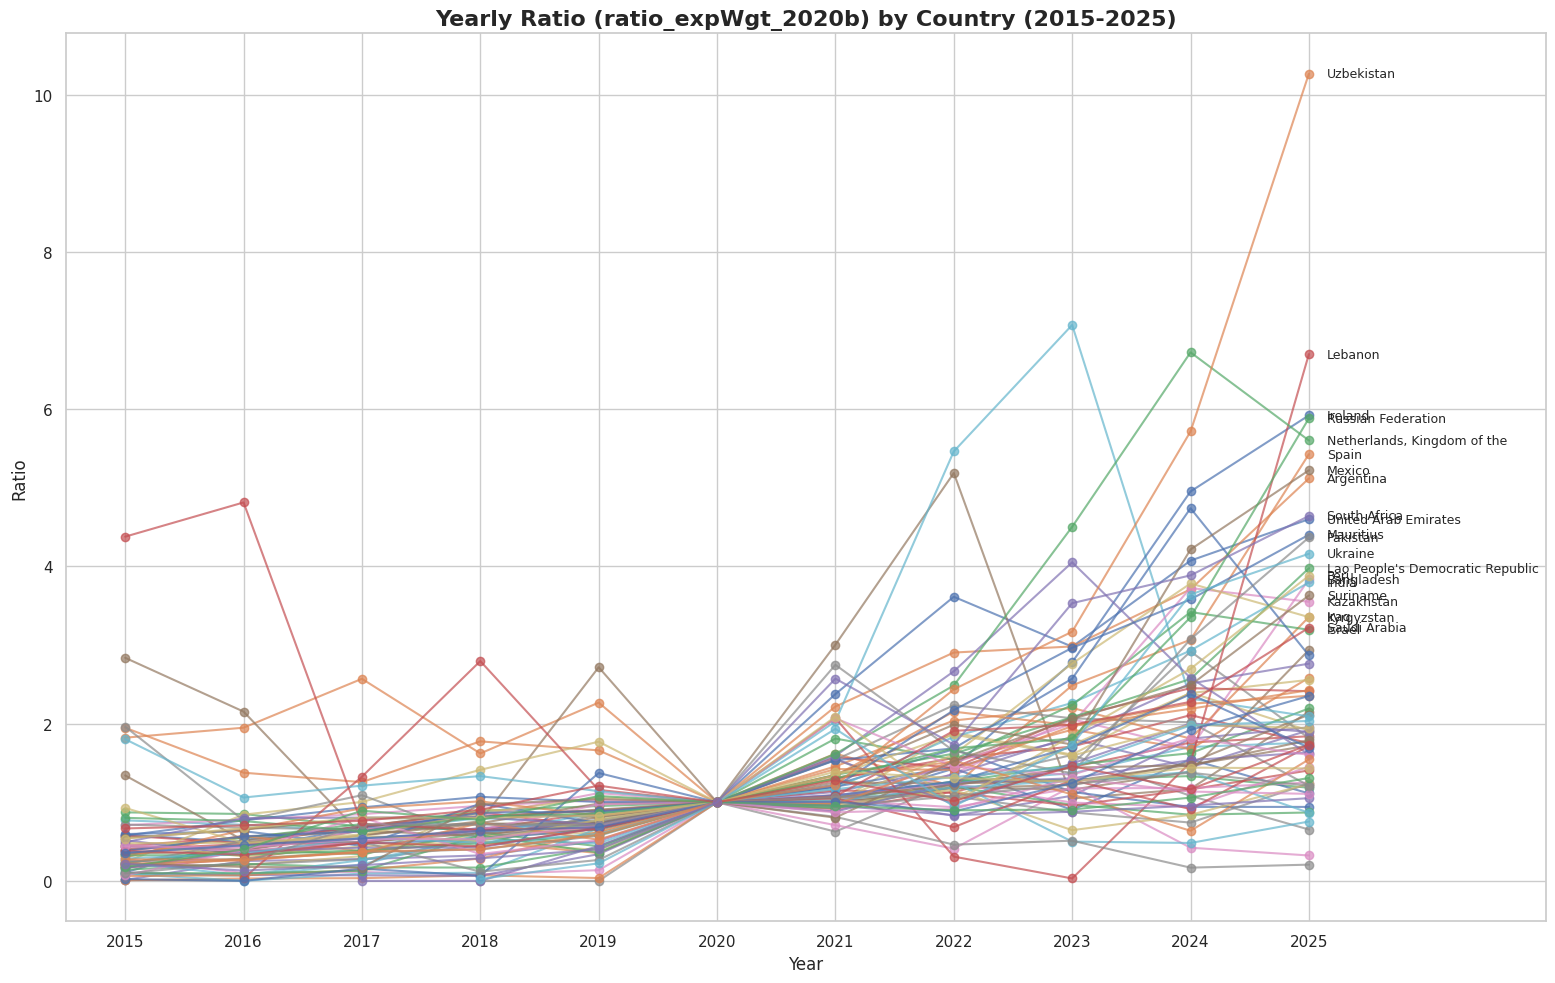

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# pivoted_df의 연도 컬럼은 정수(int) 형태이므로 리스트를 정수형으로 지정합니다.
years = list(range(2015, 2026))

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 10))

# 각 국가별로 선그래프 그리기
for idx, row in pivoted_df.iterrows():
    # x축은 연도(숫자), y축은 해당 국가의 연도별 값
    y_values = row[years].values.astype(float)
    x_values = years

    # 선그래프 그리기
    plt.plot(x_values, y_values, marker='o', alpha=0.7, label=row['name'])

    # 2025년(마지막) 데이터 위치에 국가명 직접 표시
    if not pd.isna(y_values[-1]):
        # 겹침 방지를 위해 값이 일정 기준 이상(예: 3.0 이상)인 국가의 이름만 노출하거나 전체 노출
        # 여기서는 가독성을 위해 3.0 이상인 국가들만 텍스트 레이블을 붙이도록 필터링을 줄 수 있습니다.
        # 만약 전체 국가 노출을 원하시면 조건문(if y_values[-1] > 3.0)을 제거하면 됩니다.
        if y_values[-1] > 3.0:
            plt.text(
                x=2025.15,
                y=y_values[-1],
                s=row['name'],
                fontsize=9,
                va='center'
            )

plt.title('Yearly Ratio (ratio_expWgt_2020b) by Country (2015-2025)', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Ratio', fontsize=12)
plt.xticks(range(2015, 2026))
plt.xlim(2014.5, 2027)  # 우측 국가명 공간 확보
plt.tight_layout()
plt.show()

PC1 설명력: 31.90%
PC2 설명력: 29.67%


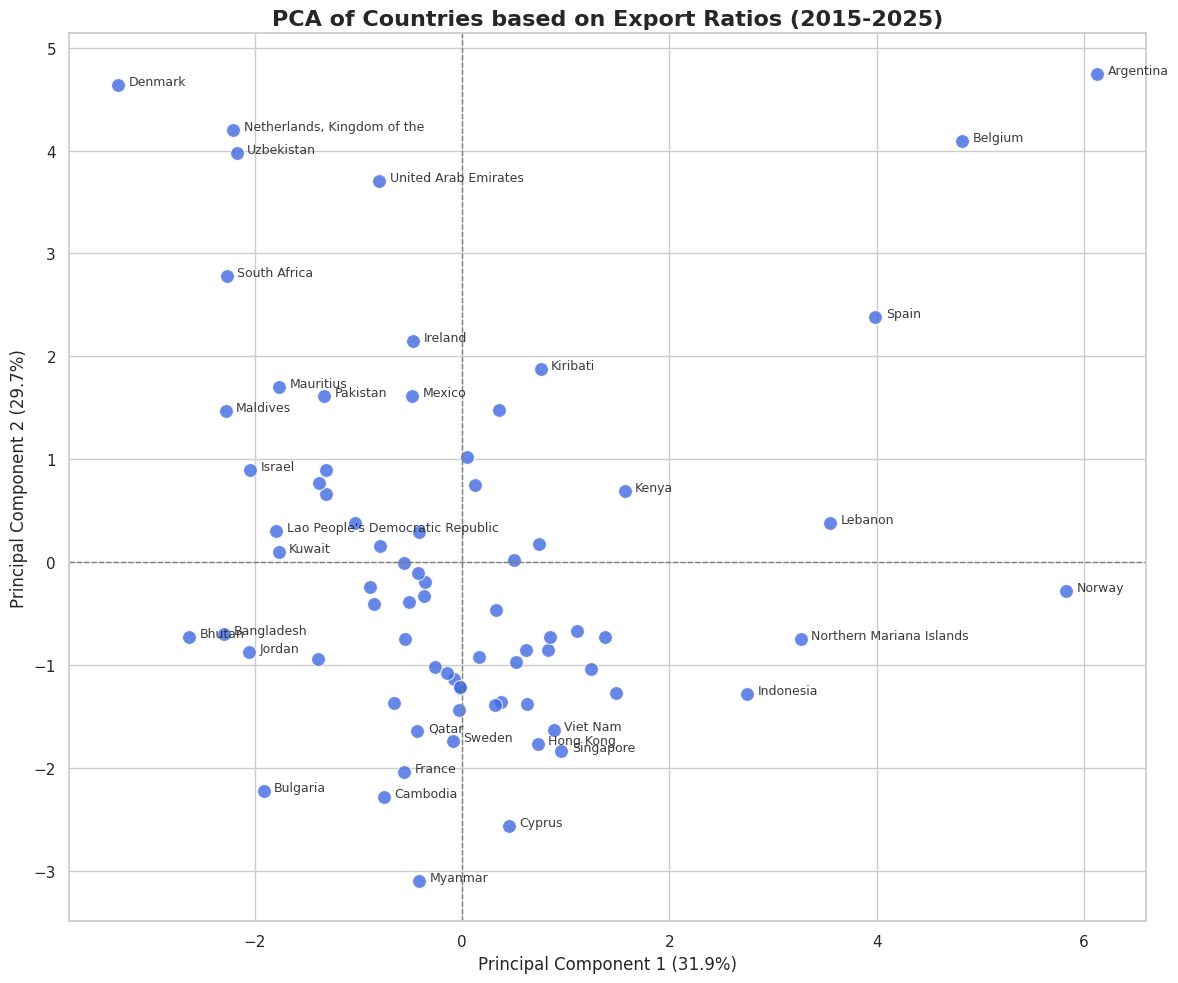

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. PCA 대상 컬럼 지정 (2015 ~ 2025)
years = list(range(2015, 2026))

# 2. 데이터 추출 및 결측치 처리 (연도별 평균값으로 결측치 대체)
X = pivoted_df[years].copy()
X_imputed = X.fillna(X.mean())

# 3. 데이터 표준화 (스케일링)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# 4. PCA 수행 (주성분 개수: 2)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

# 5. 결과를 데이터프레임으로 변환
pca_df = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2'])
pca_df['name'] = pivoted_df['name']
pca_df['iso3c'] = pivoted_df['iso3c']

# 설명력(Explained Variance Ratio) 확인
var_exp = pca.explained_variance_ratio_
print(f"PC1 설명력: {var_exp[0]*100:.2f}%")
print(f"PC2 설명력: {var_exp[1]*100:.2f}%")

# 6. 2차원 시각화
plt.figure(figsize=(12, 10))
sns.set_theme(style="whitegrid")

# 산점도 그리기
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    s=100,
    alpha=0.8,
    color='royalblue'
)

# 그래프에 각 국가명 표시 (겹침 방지를 위해 극단적인 위치나 주요 국가들 위주로 표시)
# 여기서는 PC1 또는 PC2의 절대값이 큰 주도적인 국가들을 표시합니다.
for i, row in pca_df.iterrows():
    if abs(row['PC1']) > 1.5 or abs(row['PC2']) > 1.5:
        plt.text(
            row['PC1'] + 0.1,
            row['PC2'],
            row['name'],
            fontsize=9,
            alpha=0.9
        )

plt.title('PCA of Countries based on Export Ratios (2015-2025)', fontsize=16, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({var_exp[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({var_exp[1]*100:.1f}%)', fontsize=12)
plt.axhline(0, color='grey', linestyle='--', linewidth=1)
plt.axvline(0, color='grey', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

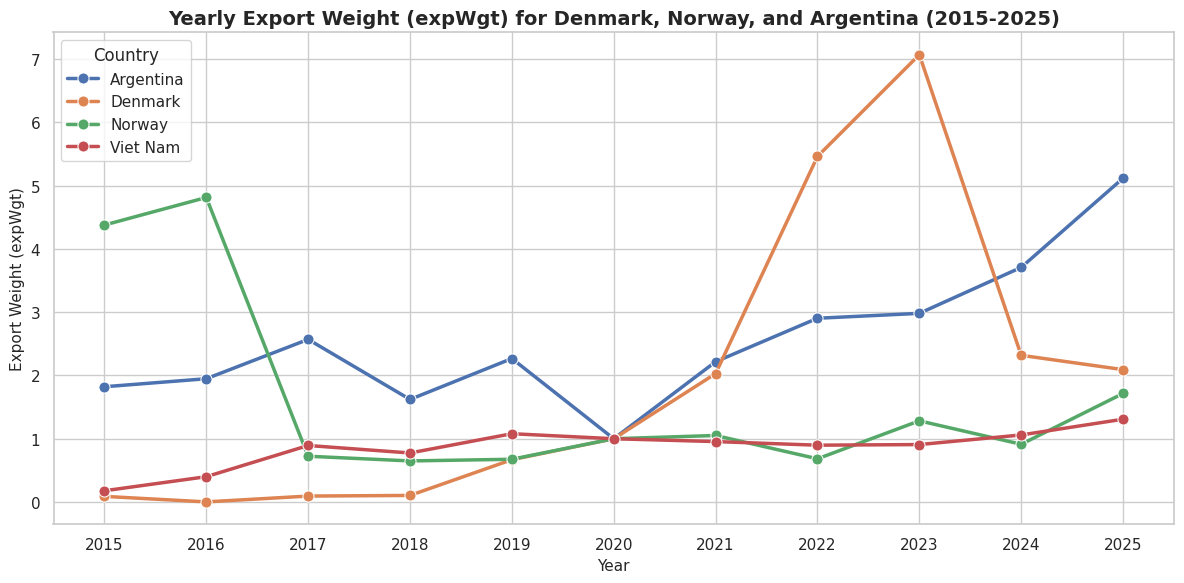

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. 대상 국가 리스트 필터링 (오타 가능성이 있는 Argentina를 포함하여 정확한 이름으로 필터링)
# target_countries = ['Viet Nam','Denmark']
target_countries = ['Viet Nam','Denmark', 'Norway', 'Argentina']
filtered_df = df[df['name'].isin(target_countries)].copy()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# 2. 선그래프 그리기 (각 선의 색상을 명확하게 구분하기 위해 hue='name' 지정)
sns.lineplot(
    data=filtered_df,
    x='Year',
    # y='expWgt',
    y='ratio_expWgt_2020b',
    hue='name',
    marker='o',
    linewidth=2.5,
    markersize=8
)

# 3. 그래프 제목 및 레이블 설정
plt.title('Yearly Export Weight (expWgt) for Denmark, Norway, and Argentina (2015-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Export Weight (expWgt)', fontsize=11)
plt.xticks(range(2015, 2026))
plt.legend(title='Country', loc='upper left')
plt.tight_layout()
plt.show()

### 마할라노비스 거리(Mahalanobis Distance)

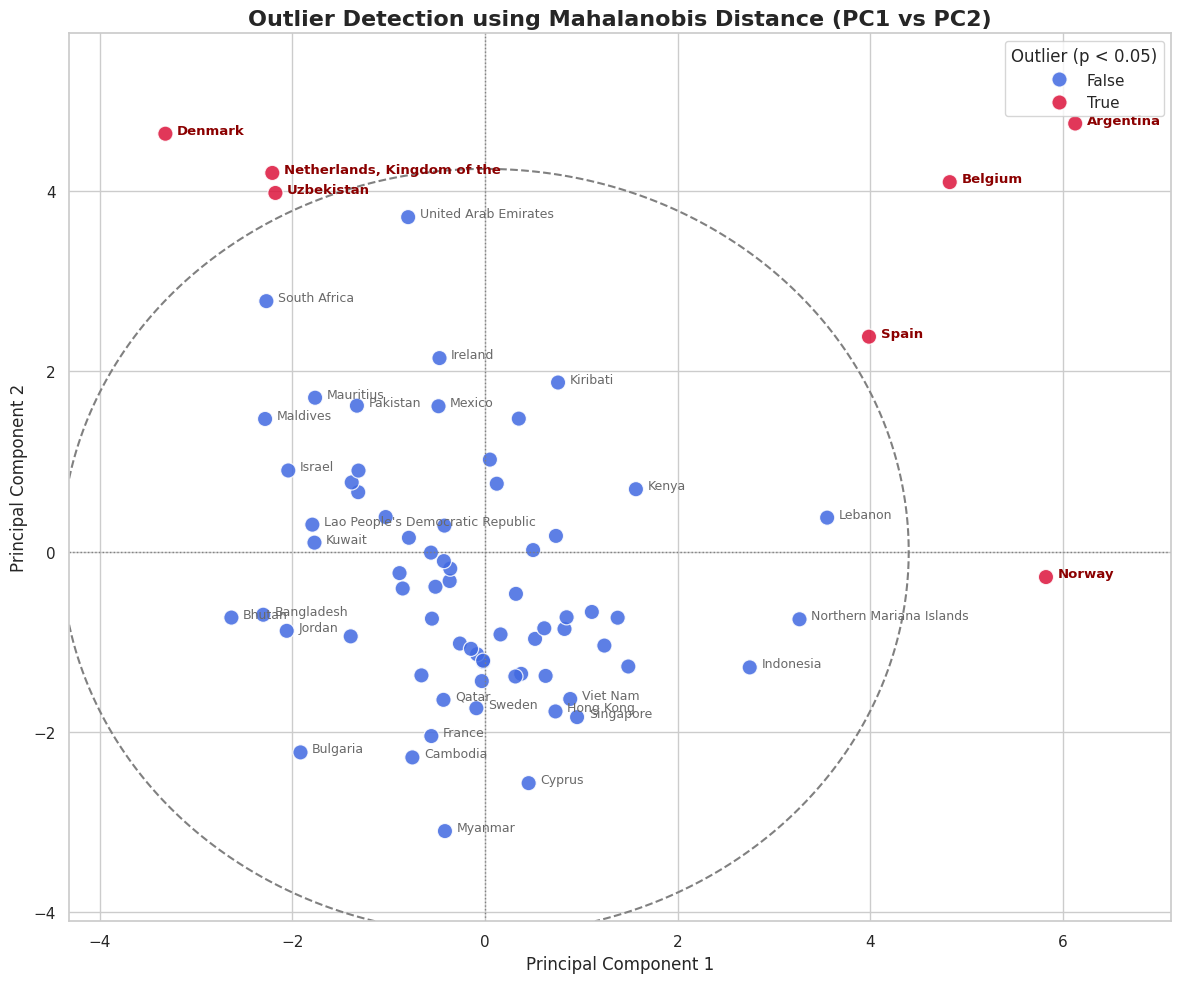

=== Detected Outliers ===


,name,iso3c,Mahalanobis
1,Argentina,ARG,4.372924
5,Belgium,BEL,3.576637
19,Denmark,DNK,3.248573
53,Norway,NOR,3.244837
52,"Netherlands, Kingdom of the",NLD,2.715861
21,Spain,ESP,2.609678
71,Uzbekistan,UZB,2.593903


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2

# 1. PCA 결과 데이터 준비 (PC1, PC2)
features = pca_df[['PC1', 'PC2']].values

# 2. 평균 및 공분산 행렬 계산
mean_vec = np.mean(features, axis=0)
cov_matrix = np.cov(features, rowvar=False)
cov_matrix_inv = np.linalg.inv(cov_matrix)

# 3. 각 관측치별 마할라노비스 거리 계산
mahal_distances = []
for x in features:
    diff = x - mean_vec
    distance = np.sqrt(diff.dot(cov_matrix_inv).dot(diff))
    mahal_distances.append(distance)

pca_df['Mahalanobis'] = mahal_distances

# 4. 임계값(Cut-off) 설정 (자유도 2인 카이제곱 분포의 95% 분위수 사용)
dof = 2  # PC1, PC2 총 2개 변수
cutoff = np.sqrt(chi2.ppf(0.95, df=dof))
pca_df['Is_Outlier'] = pca_df['Mahalanobis'] > cutoff

# 5. 결과 시각화
plt.figure(figsize=(12, 10))
sns.set_theme(style="whitegrid")

# 일반 데이터와 이상치(Outlier) 구분하여 플로팅
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Is_Outlier',
    palette={False: 'royalblue', True: 'crimson'},
    s=120,
    alpha=0.85
)

# 타원 그리기용 격자 생성 (이상치 판별 기준선 시각화)
x_min, x_max = pca_df['PC1'].min() - 1, pca_df['PC1'].max() + 1
y_min, y_max = pca_df['PC2'].min() - 1, pca_df['PC2'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# 격자 위의 마할라노비스 거리 계산
grid_distances = []
for pt in grid_points:
    diff = pt - mean_vec
    dist = np.sqrt(diff.dot(cov_matrix_inv).dot(diff))
    grid_distances.append(dist)
grid_distances = np.array(grid_distances).reshape(xx.shape)

# 마할라노비스 기준선(타원) 추가
plt.contour(xx, yy, grid_distances, levels=[cutoff], colors='grey', linestyles='dashed', linewidths=1.5)

# 검출된 이상치 및 주요 국가명 레이블 추가
for i, row in pca_df.iterrows():
    if row['Is_Outlier']:
        plt.text(
            row['PC1'] + 0.12,
            row['PC2'],
            row['name'],
            fontsize=9.5,
            color='darkred',
            fontweight='bold'
        )
    elif abs(row['PC1']) > 1.5 or abs(row['PC2']) > 1.5:
        # 외곽에 있으나 이상치 통과를 아깝게 안 한 경우 등 가독성을 위한 레이블링
        plt.text(
            row['PC1'] + 0.12,
            row['PC2'],
            row['name'],
            fontsize=9,
            color='dimgrey'
        )

plt.title('Outlier Detection using Mahalanobis Distance (PC1 vs PC2)', fontsize=16, fontweight='bold')
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.axhline(0, color='grey', linestyle=':', linewidth=1)
plt.axvline(0, color='grey', linestyle=':', linewidth=1)
plt.legend(title='Outlier (p < 0.05)', loc='upper right')
plt.tight_layout()
plt.show()

# 이상치 판별된 국가 목록 확인
outliers_list = pca_df[pca_df['Is_Outlier']][['name', 'iso3c', 'Mahalanobis']]
print("=== Detected Outliers ===")
display(outliers_list.sort_values(by='Mahalanobis', ascending=False))


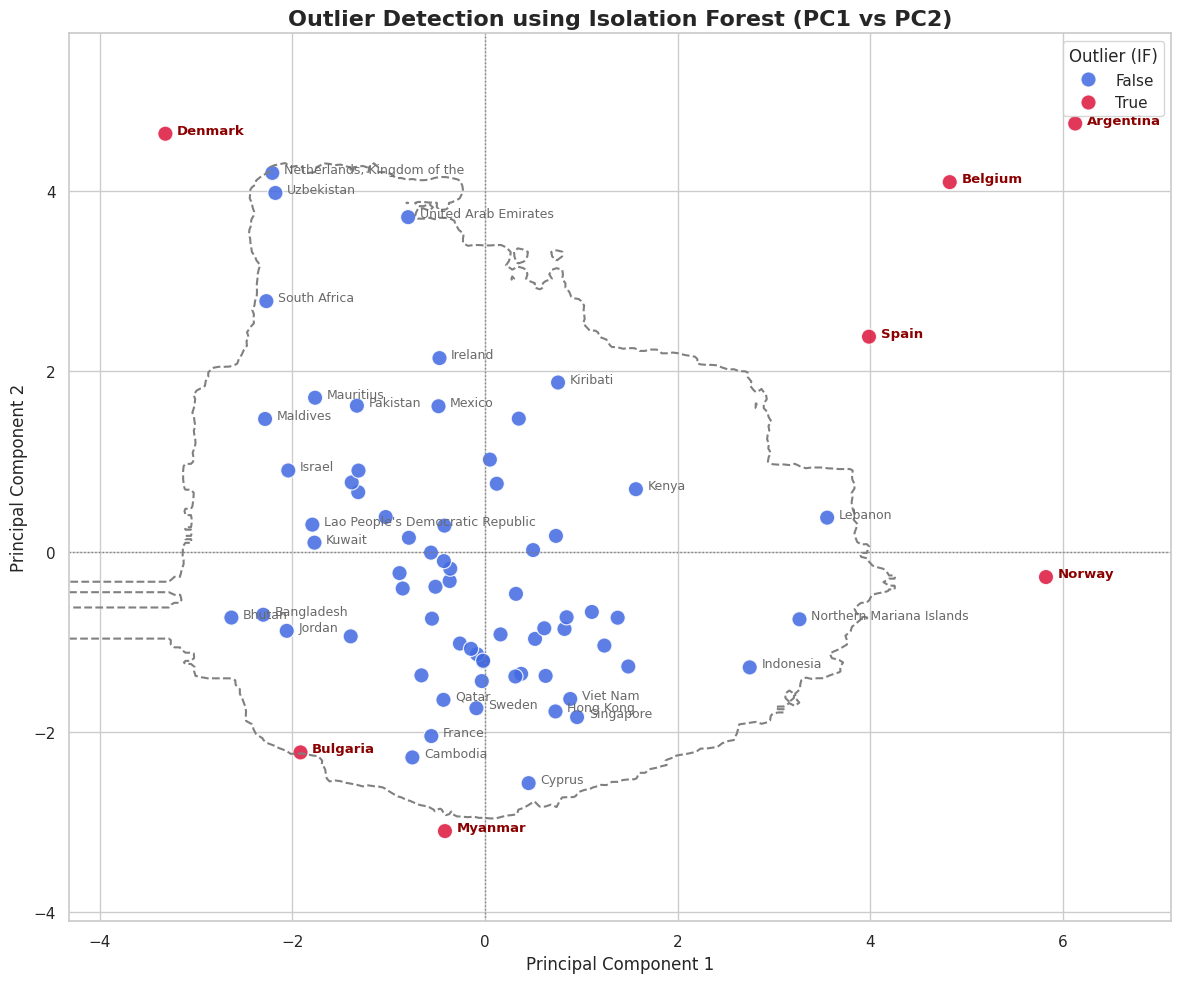

=== Detected Outliers by Isolation Forest ===


,name,iso3c
1,Argentina,ARG
5,Belgium,BEL
7,Bulgaria,BGR
19,Denmark,DNK
21,Spain,ESP
47,Myanmar,MMR
53,Norway,NOR


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

# 1. PCA 결과 데이터 준비
features = pca_df[['PC1', 'PC2']].values

# 2. Isolation Forest 모델 학습
# contamination: 이상치로 예상되는 비율 (약 9%로 설정하여 이전 결과 규모와 유사하게 맞춤)
iso_forest = IsolationForest(n_estimators=100, contamination=0.09, random_state=42)
iso_forest.fit(features)

# 이상치 예측 (1: 정상 데이터, -1: 이상치)
preds = iso_forest.predict(features)
pca_df['Is_Outlier_IF'] = preds == -1

# 3. 시각화를 위한 격자 지도 및 결정 경계(Decision Boundary) 계산
x_min, x_max = pca_df['PC1'].min() - 1, pca_df['PC1'].max() + 1
y_min, y_max = pca_df['PC2'].min() - 1, pca_df['PC2'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# 격자 상의 각 위치에 대해 Isolation Forest의 Anomaly Score 계산
Z = iso_forest.decision_function(grid_points)
Z = Z.reshape(xx.shape)

# 4. 결과 시각화
plt.figure(figsize=(12, 10))
sns.set_theme(style="whitegrid")

# Isolation Forest 결정 경계(이상치 판별 기준선) 플로팅
plt.contour(xx, yy, Z, levels=[0], colors='grey', linestyles='dashed', linewidths=1.5)

# 일반 데이터와 Isolation Forest 이상치 포인트 구분하여 그리기
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Is_Outlier_IF',
    palette={False: 'royalblue', True: 'crimson'},
    s=120,
    alpha=0.85
)

# 이상치 국가 및 외곽 주요 국가 텍스트 레이블링
for i, row in pca_df.iterrows():
    if row['Is_Outlier_IF']:
        plt.text(
            row['PC1'] + 0.12,
            row['PC2'],
            row['name'],
            fontsize=9.5,
            color='darkred',
            fontweight='bold'
        )
    elif abs(row['PC1']) > 1.5 or abs(row['PC2']) > 1.5:
        plt.text(
            row['PC1'] + 0.12,
            row['PC2'],
            row['name'],
            fontsize=9,
            color='dimgrey'
        )

plt.title('Outlier Detection using Isolation Forest (PC1 vs PC2)', fontsize=16, fontweight='bold')
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.axhline(0, color='grey', linestyle=':', linewidth=1)
plt.axvline(0, color='grey', linestyle=':', linewidth=1)
plt.legend(title='Outlier (IF)', loc='upper right')
plt.tight_layout()
plt.show()

# 검출된 이상치 리스트 출력
if_outliers = pca_df[pca_df['Is_Outlier_IF']][['name', 'iso3c']]
print("=== Detected Outliers by Isolation Forest ===")
display(if_outliers)


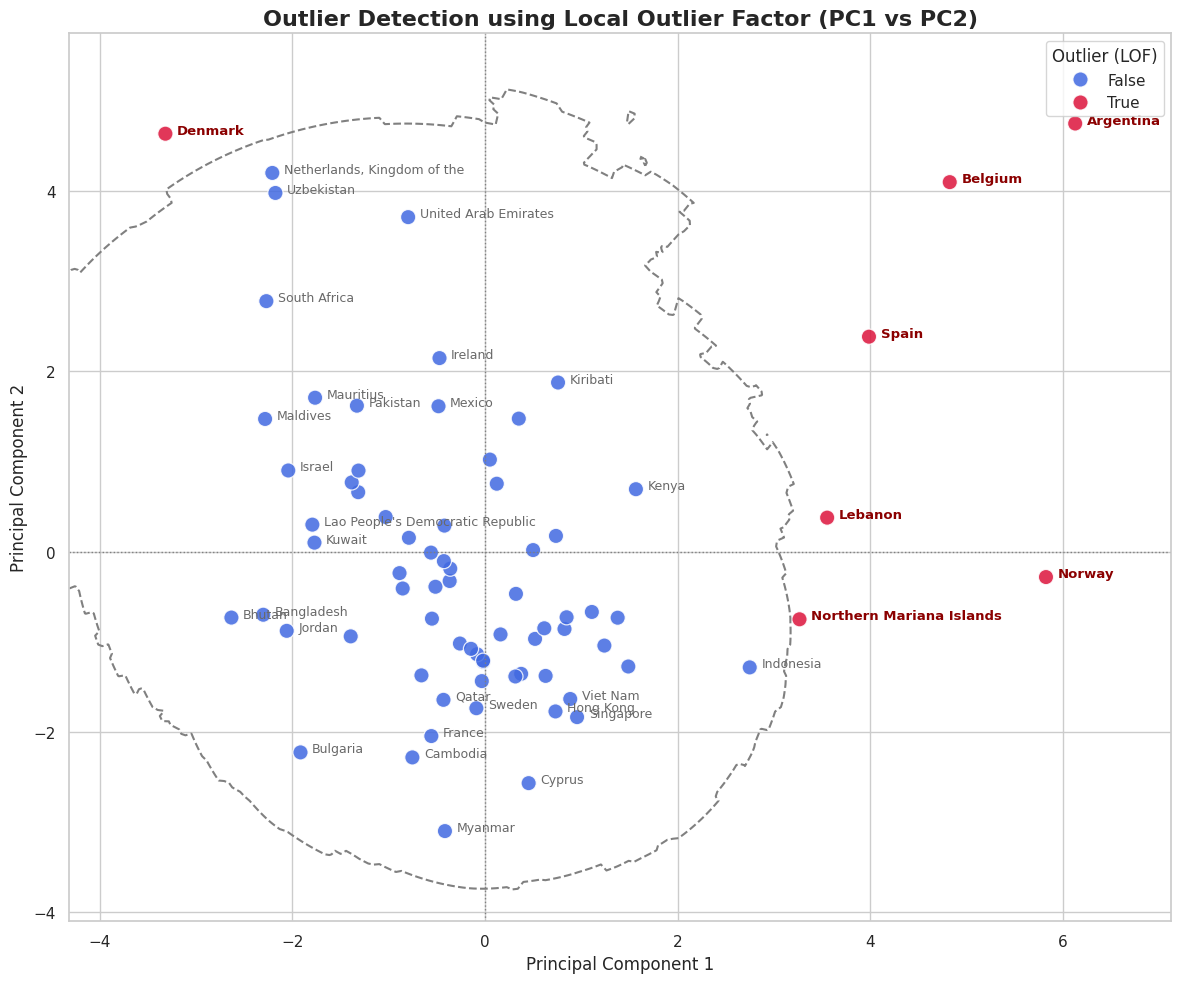

=== Detected Outliers by Local Outlier Factor ===


,name,iso3c
1,Argentina,ARG
5,Belgium,BEL
19,Denmark,DNK
21,Spain,ESP
43,Lebanon,LBN
49,Northern Mariana Islands,MNP
53,Norway,NOR


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import LocalOutlierFactor

# 1. PCA 결과 데이터 준비
features = pca_df[['PC1', 'PC2']].values

# 2. Local Outlier Factor (LOF) 모델 학습 및 예측
# novelty=True 설정을 통해 그리드 맵상에 결정 경계를 그릴 수 있도록 만듭니다.
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.09, novelty=True)
lof.fit(features)

# 이상치 예측 (1: 정상 데이터, -1: 이상치)
preds = lof.predict(features)
pca_df['Is_Outlier_LOF'] = preds == -1

# 3. 시각화를 위한 격자 지도 및 결정 경계(Decision Boundary) 계산
x_min, x_max = pca_df['PC1'].min() - 1, pca_df['PC1'].max() + 1
y_min, y_max = pca_df['PC2'].min() - 1, pca_df['PC2'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# 격자 위의 각 포인트에 대해 LOF의 결정 함수 값 계산
Z = lof.decision_function(grid_points)
Z = Z.reshape(xx.shape)

# 4. 결과 시각화
plt.figure(figsize=(12, 10))
sns.set_theme(style="whitegrid")

# LOF 결정 경계 (임계값 0 기준선) 그리기
plt.contour(xx, yy, Z, levels=[0], colors='grey', linestyles='dashed', linewidths=1.5)

# 일반 데이터와 LOF 이상치 포인트 구분하여 시각화
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Is_Outlier_LOF',
    palette={False: 'royalblue', True: 'crimson'},
    s=120,
    alpha=0.85
)

# 검출된 이상치 및 주요 외곽 국가명 레이블 추가
for i, row in pca_df.iterrows():
    if row['Is_Outlier_LOF']:
        plt.text(
            row['PC1'] + 0.12,
            row['PC2'],
            row['name'],
            fontsize=9.5,
            color='darkred',
            fontweight='bold'
        )
    elif abs(row['PC1']) > 1.5 or abs(row['PC2']) > 1.5:
        plt.text(
            row['PC1'] + 0.12,
            row['PC2'],
            row['name'],
            fontsize=9,
            color='dimgrey'
        )

plt.title('Outlier Detection using Local Outlier Factor (PC1 vs PC2)', fontsize=16, fontweight='bold')
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.axhline(0, color='grey', linestyle=':', linewidth=1)
plt.axvline(0, color='grey', linestyle=':', linewidth=1)
plt.legend(title='Outlier (LOF)', loc='upper right')
plt.tight_layout()
plt.show()

# 검출된 LOF 이상치 리스트 출력
lof_outliers = pca_df[pca_df['Is_Outlier_LOF']][['name', 'iso3c']]
print("=== Detected Outliers by Local Outlier Factor ===")
display(lof_outliers)
